<a href="https://colab.research.google.com/github/HashimK1411/MSc_Project/blob/main/03_RF_H2_CICIDS2017.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Cell 1 — Environment check

import sys
import tensorflow as tf

print(
    "Python version:",
    sys.version
)

print(
    "TensorFlow version:",
    tf.__version__
)

print(
    "GPU devices:",
    tf.config.list_physical_devices("GPU")
)

!nvidia-smi

Python version: 3.12.13 (main, Mar  4 2026, 09:23:07) [GCC 11.4.0]
TensorFlow version: 2.19.0
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Fri Sep 25 15:17:24 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   41C    P8              9W /   70W |       3MiB /  

In [ ]:
# Cell 2 — Install and import libraries

!pip install -q tensorflow_decision_forests==1.12.0 pyarrow

import os
import time
import gc

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf
import tensorflow_decision_forests as tfdf

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    matthews_corrcoef,
    classification_report,
    ConfusionMatrixDisplay
)

print(
    "TensorFlow:",
    tf.__version__
)

print(
    "TF-DF:",
    tfdf.__version__
)


TensorFlow: 2.19.0
TF-DF: 1.12.0


In [ ]:
# Cell 3 — Mount Google Drive

from google.colab import drive

drive.mount(
    "/content/drive"
)

Mounted at /content/drive


In [ ]:
# Cell 4 — Define paths

PROJECT_DIR = (
    "/content/drive/MyDrive/MSc_Project"
)

PROCESSED_DIR = os.path.join(
    PROJECT_DIR,
    "data",
    "CICIDS2017",
    "processed"
)

RESULTS_DIR = os.path.join(
    PROJECT_DIR,
    "results",
    "RF_H2_CIC"
)

MODEL_DIR = os.path.join(
    PROJECT_DIR,
    "models",
    "RF_H2_CIC"
)

os.makedirs(
    RESULTS_DIR,
    exist_ok=True
)

os.makedirs(
    MODEL_DIR,
    exist_ok=True
)

TRAIN_PATH = os.path.join(
    PROCESSED_DIR,
    "cicids2017_train.parquet"
)

VAL_PATH = os.path.join(
    PROCESSED_DIR,
    "cicids2017_validation.parquet"
)

TEST_PATH = os.path.join(
    PROCESSED_DIR,
    "cicids2017_test.parquet"
)

H1_100_REFERENCE_PATH = os.path.join(
    PROJECT_DIR,
    "results",
    "RF_H1_CIC",
    "RF_H1_100_validation.csv"
)

LABEL_COL = "Label"

print(
    "Training:",
    TRAIN_PATH
)

print(
    "Validation:",
    VAL_PATH
)

print(
    "Testing:",
    TEST_PATH
)

print(
    "H1-100 reference:",
    H1_100_REFERENCE_PATH
)

print(
    "H2 results:",
    RESULTS_DIR
)

Training: /content/drive/MyDrive/MSc_Project/data/CICIDS2017/processed/cicids2017_train.parquet
Validation: /content/drive/MyDrive/MSc_Project/data/CICIDS2017/processed/cicids2017_validation.parquet
Testing: /content/drive/MyDrive/MSc_Project/data/CICIDS2017/processed/cicids2017_test.parquet
H1-100 reference: /content/drive/MyDrive/MSc_Project/results/RF_H1_CIC/RF_H1_100_validation.csv
H2 results: /content/drive/MyDrive/MSc_Project/results/RF_H2_CIC


In [ ]:
# Cell 5 — Verify files

print(
    "Train exists:",
    os.path.exists(TRAIN_PATH)
)

print(
    "Validation exists:",
    os.path.exists(VAL_PATH)
)

print(
    "Test exists:",
    os.path.exists(TEST_PATH)
)

print(
    "H1-100 reference exists:",
    os.path.exists(
        H1_100_REFERENCE_PATH
    )
)

Train exists: True
Validation exists: True
Test exists: True
H1-100 reference exists: True


In [ ]:
# Cell 6 — Load frozen datasets

print(
    "Loading training data..."
)

train_df = pd.read_parquet(
    TRAIN_PATH
)

print(
    "Loading validation data..."
)

val_df = pd.read_parquet(
    VAL_PATH
)

print(
    "Loading testing data..."
)

test_df = pd.read_parquet(
    TEST_PATH
)

print(
    "\nTraining:",
    train_df.shape
)

print(
    "Validation:",
    val_df.shape
)

print(
    "Testing:",
    test_df.shape
)

print(
    "\nNumber of classes:",
    train_df[LABEL_COL].nunique()
)

Loading training data...
Loading validation data...
Loading testing data...

Training: (1764554, 79)
Validation: (378119, 79)
Testing: (378119, 79)

Number of classes: 15


In [ ]:
# Cell 7 — Establish class order

class_names = sorted(
    train_df[LABEL_COL]
    .astype(str)
    .unique()
    .tolist()
)

for index, label in enumerate(
    class_names
):
    print(
        index,
        "->",
        label
    )

print(
    "\nNumber of classes:",
    len(class_names)
)

0 -> BENIGN
1 -> Bot
2 -> DDoS
3 -> DoS GoldenEye
4 -> DoS Hulk
5 -> DoS Slowhttptest
6 -> DoS slowloris
7 -> FTP-Patator
8 -> Heartbleed
9 -> Infiltration
10 -> PortScan
11 -> SSH-Patator
12 -> Web Attack - Brute Force
13 -> Web Attack - SQL Injection
14 -> Web Attack - XSS

Number of classes: 15


In [ ]:
# Cell 8 — Convert datasets to TF-DF

train_ds = (
    tfdf.keras
    .pd_dataframe_to_tf_dataset(
        train_df,
        label=LABEL_COL,
        task=tfdf.keras.Task.CLASSIFICATION
    )
)

val_ds = (
    tfdf.keras
    .pd_dataframe_to_tf_dataset(
        val_df,
        label=LABEL_COL,
        task=tfdf.keras.Task.CLASSIFICATION
    )
)

test_ds = (
    tfdf.keras
    .pd_dataframe_to_tf_dataset(
        test_df,
        label=LABEL_COL,
        task=tfdf.keras.Task.CLASSIFICATION
    )
)

print(
    "TF-DF datasets created successfully."
)

TF-DF datasets created successfully.


In [ ]:
# Cell 9 — Validation metric helper

def evaluate_candidate(
    model,
    dataset,
    dataframe,
    class_names
):

    pred_probabilities = model.predict(
        dataset,
        verbose=0
    )

    pred_ids = np.argmax(
        pred_probabilities,
        axis=1
    )

    y_pred = np.array(
        class_names
    )[pred_ids]

    y_true = (
        dataframe[LABEL_COL]
        .astype(str)
        .to_numpy()
    )

    return {
        "Accuracy":
            accuracy_score(
                y_true,
                y_pred
            ),

        "Macro Precision":
            precision_score(
                y_true,
                y_pred,
                average="macro",
                zero_division=0
            ),

        "Macro Recall":
            recall_score(
                y_true,
                y_pred,
                average="macro",
                zero_division=0
            ),

        "Macro F1":
            f1_score(
                y_true,
                y_pred,
                average="macro",
                zero_division=0
            ),

        "Weighted F1":
            f1_score(
                y_true,
                y_pred,
                average="weighted",
                zero_division=0
            ),

        "Balanced Accuracy":
            balanced_accuracy_score(
                y_true,
                y_pred
            ),

        "MCC":
            matthews_corrcoef(
                y_true,
                y_pred
            )
    }

In [ ]:
# Cell 10 — Load unlimited-depth reference

reference_df = pd.read_csv(
    H1_100_REFERENCE_PATH
)

print(
    "Existing 100-tree unlimited-depth "
    "validation result:"
)

display(
    reference_df
)

Existing 100-tree unlimited-depth validation result:


,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1,Balanced Accuracy,MCC,Trees,Training Time Seconds
0,0.998553,0.941933,0.831298,0.865672,0.998526,0.831298,0.995188,100,298.754683


In [ ]:
# Cell 11 — Train RF-H2-D10
# 100 trees, max_depth=10, min_examples=1

rf_h2_d10 = tfdf.keras.RandomForestModel(
    num_trees=100,
    max_depth=10,
    min_examples=1,
    num_candidate_attributes=0,
    bootstrap_training_dataset=True,
    bootstrap_size_ratio=1.0,
    sampling_with_replacement=True,
    random_seed=42,
    compute_oob_performances=True,
    verbose=2
)

rf_h2_d10.compile(
    metrics=["accuracy"]
)

start_time = time.time()

rf_h2_d10.fit(
    train_ds
)

time_d10 = (
    time.time() - start_time
)

print(
    f"\nRF-H2-D10 training time: "
    f"{time_d10:.2f} seconds"
)

Use 8 thread(s) for training
Use /tmp/tmp0w6e82i6 as temporary training directory
Reading training dataset...
Training tensor examples:
Features: {'Destination_Port': <tf.Tensor 'data:0' shape=(None,) dtype=float32>, 'Flow_Duration': <tf.Tensor 'data_1:0' shape=(None,) dtype=float64>, 'Total_Fwd_Packets': <tf.Tensor 'data_2:0' shape=(None,) dtype=float32>, 'Total_Backward_Packets': <tf.Tensor 'data_3:0' shape=(None,) dtype=float32>, 'Total_Length_of_Fwd_Packets': <tf.Tensor 'data_4:0' shape=(None,) dtype=float32>, 'Total_Length_of_Bwd_Packets': <tf.Tensor 'data_5:0' shape=(None,) dtype=float64>, 'Fwd_Packet_Length_Max': <tf.Tensor 'data_6:0' shape=(None,) dtype=float32>, 'Fwd_Packet_Length_Min': <tf.Tensor 'data_7:0' shape=(None,) dtype=float32>, 'Fwd_Packet_Length_Mean': <tf.Tensor 'data_8:0' shape=(None,) dtype=float32>, 'Fwd_Packet_Length_Std': <tf.Tensor 'data_9:0' shape=(None,) dtype=float32>, 'Bwd_Packet_Length_Max': <tf.Tensor 'data_10:0' shape=(None,) dtype=float32>, 'Bwd_Packe

I0000 00:00:1790350123.601346     252 kernel.cc:782] Start Yggdrasil model training
I0000 00:00:1790350123.601683     252 kernel.cc:783] Collect training examples
I0000 00:00:1790350123.601699     252 kernel.cc:795] Dataspec guide:
column_guides {
  column_name_pattern: "^__LABEL$"
  type: CATEGORICAL
  categorial {
    min_vocab_frequency: 0
    max_vocab_count: -1
  }
}
default_column_guide {
  categorial {
    max_vocab_count: 2000
  }
  discretized_numerical {
    maximum_num_bins: 255
  }
}
ignore_columns_without_guides: false
detect_numerical_as_discretized_numerical: false

I0000 00:00:1790350123.602648     252 kernel.cc:401] Number of batches: 1765
I0000 00:00:1790350123.602675     252 kernel.cc:402] Number of examples: 1764554
I0000 00:00:1790350124.714446     252 kernel.cc:802] Training dataset:
Number of records: 1764554
Number of columns: 79

Number of columns by type:
	NUMERICAL: 78 (98.7342%)
	CATEGORICAL: 1 (1.26582%)

Columns:

NUMERICAL: 78 (98.7342%)
	0: "ACK_Flag_Cou

Model trained in 0:02:51.349941
Compiling model...
Model compiled.

RF-H2-D10 training time: 250.06 seconds


In [ ]:
# Cell 12 — Validate RF-H2-D10

results_d10 = evaluate_candidate(
    rf_h2_d10,
    val_ds,
    val_df,
    class_names
)

results_d10[
    "Max Depth"
] = 10

results_d10[
    "Min Examples"
] = 1

results_d10[
    "Trees"
] = 100

results_d10[
    "Training Time Seconds"
] = time_d10

print(
    "RF-H2-D10 Validation Results"
)

display(
    pd.DataFrame(
        [results_d10]
    )
)

RF-H2-D10 Validation Results


,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1,Balanced Accuracy,MCC,Max Depth,Min Examples,Trees,Training Time Seconds
0,0.996297,0.727388,0.636193,0.664491,0.995724,0.636193,0.987637,10,1,100,250.064259


In [ ]:
# Cell 13 — Save RF-H2-D10 validation result and clear model

D10_RESULT_PATH = os.path.join(
    RESULTS_DIR,
    "RF_H2_D10_validation.csv"
)

pd.DataFrame(
    [results_d10]
).to_csv(
    D10_RESULT_PATH,
    index=False
)

print(
    "RF-H2-D10 validation result saved to:"
)

print(
    D10_RESULT_PATH
)

print(
    "\nFile exists:",
    os.path.exists(D10_RESULT_PATH)
)

del rf_h2_d10

gc.collect()

print(
    "\nRF-H2-D10 removed from RAM."
)

RF-H2-D10 validation result saved to:
/content/drive/MyDrive/MSc_Project/results/RF_H2_CIC/RF_H2_D10_validation.csv

File exists: True

RF-H2-D10 removed from RAM.


In [ ]:
# Cell 14 — Train RF-H2-D20
# 100 trees, max_depth=20, min_examples=1

rf_h2_d20 = tfdf.keras.RandomForestModel(
    num_trees=100,
    max_depth=20,
    min_examples=1,
    num_candidate_attributes=0,
    bootstrap_training_dataset=True,
    bootstrap_size_ratio=1.0,
    sampling_with_replacement=True,
    random_seed=42,
    compute_oob_performances=True,
    verbose=2
)

rf_h2_d20.compile(
    metrics=["accuracy"]
)

start_time = time.time()

rf_h2_d20.fit(
    train_ds
)

time_d20 = (
    time.time() - start_time
)

print(
    f"\nRF-H2-D20 training time: "
    f"{time_d20:.2f} seconds"
)

Use 8 thread(s) for training
Use /tmp/tmpqgqk9oqh as temporary training directory
Reading training dataset...
Training tensor examples:
Features: {'Destination_Port': <tf.Tensor 'data:0' shape=(None,) dtype=float32>, 'Flow_Duration': <tf.Tensor 'data_1:0' shape=(None,) dtype=float64>, 'Total_Fwd_Packets': <tf.Tensor 'data_2:0' shape=(None,) dtype=float32>, 'Total_Backward_Packets': <tf.Tensor 'data_3:0' shape=(None,) dtype=float32>, 'Total_Length_of_Fwd_Packets': <tf.Tensor 'data_4:0' shape=(None,) dtype=float32>, 'Total_Length_of_Bwd_Packets': <tf.Tensor 'data_5:0' shape=(None,) dtype=float64>, 'Fwd_Packet_Length_Max': <tf.Tensor 'data_6:0' shape=(None,) dtype=float32>, 'Fwd_Packet_Length_Min': <tf.Tensor 'data_7:0' shape=(None,) dtype=float32>, 'Fwd_Packet_Length_Mean': <tf.Tensor 'data_8:0' shape=(None,) dtype=float32>, 'Fwd_Packet_Length_Std': <tf.Tensor 'data_9:0' shape=(None,) dtype=float32>, 'Bwd_Packet_Length_Max': <tf.Tensor 'data_10:0' shape=(None,) dtype=float32>, 'Bwd_Packe

I0000 00:00:1790351892.125620     252 kernel.cc:782] Start Yggdrasil model training
I0000 00:00:1790351892.125665     252 kernel.cc:783] Collect training examples
I0000 00:00:1790351892.125676     252 kernel.cc:795] Dataspec guide:
column_guides {
  column_name_pattern: "^__LABEL$"
  type: CATEGORICAL
  categorial {
    min_vocab_frequency: 0
    max_vocab_count: -1
  }
}
default_column_guide {
  categorial {
    max_vocab_count: 2000
  }
  discretized_numerical {
    maximum_num_bins: 255
  }
}
ignore_columns_without_guides: false
detect_numerical_as_discretized_numerical: false

I0000 00:00:1790351892.126038     252 kernel.cc:401] Number of batches: 1765
I0000 00:00:1790351892.126087     252 kernel.cc:402] Number of examples: 1764554
I0000 00:00:1790351893.212142     252 kernel.cc:802] Training dataset:
Number of records: 1764554
Number of columns: 79

Number of columns by type:
	NUMERICAL: 78 (98.7342%)
	CATEGORICAL: 1 (1.26582%)

Columns:

NUMERICAL: 78 (98.7342%)
	0: "ACK_Flag_Cou

Model trained in 0:04:00.888829
Compiling model...
Model compiled.

RF-H2-D20 training time: 315.71 seconds


In [ ]:
# Cell 15 — Validate RF-H2-D20

results_d20 = evaluate_candidate(
    rf_h2_d20,
    val_ds,
    val_df,
    class_names
)

results_d20[
    "Max Depth"
] = 20

results_d20[
    "Min Examples"
] = 1

results_d20[
    "Trees"
] = 100

results_d20[
    "Training Time Seconds"
] = time_d20

print(
    "RF-H2-D20 Validation Results"
)

display(
    pd.DataFrame(
        [results_d20]
    )
)

RF-H2-D20 Validation Results


,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1,Balanced Accuracy,MCC,Max Depth,Min Examples,Trees,Training Time Seconds
0,0.9989,0.963516,0.81759,0.849237,0.998802,0.81759,0.996343,20,1,100,315.708455


In [ ]:
# Cell 16 — Save RF-H2-D20 validation result and clear model

D20_RESULT_PATH = os.path.join(
    RESULTS_DIR,
    "RF_H2_D20_validation.csv"
)

pd.DataFrame(
    [results_d20]
).to_csv(
    D20_RESULT_PATH,
    index=False
)

print(
    "RF-H2-D20 validation result saved to:"
)

print(
    D20_RESULT_PATH
)

print(
    "\nFile exists:",
    os.path.exists(D20_RESULT_PATH)
)

del rf_h2_d20

gc.collect()

print(
    "\nRF-H2-D20 removed from RAM."
)

RF-H2-D20 validation result saved to:
/content/drive/MyDrive/MSc_Project/results/RF_H2_CIC/RF_H2_D20_validation.csv

File exists: True

RF-H2-D20 removed from RAM.


In [ ]:
# Cell 17 — Train RF-H2-D30
# 100 trees, max_depth=30, min_examples=1

rf_h2_d30 = tfdf.keras.RandomForestModel(
    num_trees=100,
    max_depth=30,
    min_examples=1,
    num_candidate_attributes=0,
    bootstrap_training_dataset=True,
    bootstrap_size_ratio=1.0,
    sampling_with_replacement=True,
    random_seed=42,
    compute_oob_performances=True,
    verbose=2
)

rf_h2_d30.compile(
    metrics=["accuracy"]
)

start_time = time.time()

rf_h2_d30.fit(
    train_ds
)

time_d30 = (
    time.time() - start_time
)

print(
    f"\nRF-H2-D30 training time: "
    f"{time_d30:.2f} seconds"
)

Use 8 thread(s) for training
Use /tmp/tmp147ikhjp as temporary training directory
Reading training dataset...
Training tensor examples:
Features: {'Destination_Port': <tf.Tensor 'data:0' shape=(None,) dtype=float32>, 'Flow_Duration': <tf.Tensor 'data_1:0' shape=(None,) dtype=float64>, 'Total_Fwd_Packets': <tf.Tensor 'data_2:0' shape=(None,) dtype=float32>, 'Total_Backward_Packets': <tf.Tensor 'data_3:0' shape=(None,) dtype=float32>, 'Total_Length_of_Fwd_Packets': <tf.Tensor 'data_4:0' shape=(None,) dtype=float32>, 'Total_Length_of_Bwd_Packets': <tf.Tensor 'data_5:0' shape=(None,) dtype=float64>, 'Fwd_Packet_Length_Max': <tf.Tensor 'data_6:0' shape=(None,) dtype=float32>, 'Fwd_Packet_Length_Min': <tf.Tensor 'data_7:0' shape=(None,) dtype=float32>, 'Fwd_Packet_Length_Mean': <tf.Tensor 'data_8:0' shape=(None,) dtype=float32>, 'Fwd_Packet_Length_Std': <tf.Tensor 'data_9:0' shape=(None,) dtype=float32>, 'Bwd_Packet_Length_Max': <tf.Tensor 'data_10:0' shape=(None,) dtype=float32>, 'Bwd_Packe

I0000 00:00:1790352674.731400     252 kernel.cc:782] Start Yggdrasil model training
I0000 00:00:1790352674.731447     252 kernel.cc:783] Collect training examples
I0000 00:00:1790352674.731460     252 kernel.cc:795] Dataspec guide:
column_guides {
  column_name_pattern: "^__LABEL$"
  type: CATEGORICAL
  categorial {
    min_vocab_frequency: 0
    max_vocab_count: -1
  }
}
default_column_guide {
  categorial {
    max_vocab_count: 2000
  }
  discretized_numerical {
    maximum_num_bins: 255
  }
}
ignore_columns_without_guides: false
detect_numerical_as_discretized_numerical: false

I0000 00:00:1790352674.731909     252 kernel.cc:401] Number of batches: 1765
I0000 00:00:1790352674.731926     252 kernel.cc:402] Number of examples: 1764554
I0000 00:00:1790352675.855980     252 kernel.cc:802] Training dataset:
Number of records: 1764554
Number of columns: 79

Number of columns by type:
	NUMERICAL: 78 (98.7342%)
	CATEGORICAL: 1 (1.26582%)

Columns:

NUMERICAL: 78 (98.7342%)
	0: "ACK_Flag_Cou

Model trained in 0:04:02.130473
Compiling model...
Model compiled.

RF-H2-D30 training time: 315.33 seconds


In [ ]:
# Cell 18 — Validate RF-H2-D30

results_d30 = evaluate_candidate(
    rf_h2_d30,
    val_ds,
    val_df,
    class_names
)

results_d30[
    "Max Depth"
] = 30

results_d30[
    "Min Examples"
] = 1

results_d30[
    "Trees"
] = 100

results_d30[
    "Training Time Seconds"
] = time_d30

print(
    "RF-H2-D30 Validation Results"
)

display(
    pd.DataFrame(
        [results_d30]
    )
)


RF-H2-D30 Validation Results


,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1,Balanced Accuracy,MCC,Max Depth,Min Examples,Trees,Training Time Seconds
0,0.99867,0.94418,0.848268,0.881331,0.998625,0.848268,0.995576,30,1,100,315.334803


In [ ]:
# Cell 19 — Save RF-H2-D30 validation checkpoint

D30_RESULT_PATH = os.path.join(
    RESULTS_DIR,
    "RF_H2_D30_validation.csv"
)

pd.DataFrame(
    [results_d30]
).to_csv(
    D30_RESULT_PATH,
    index=False
)

print(
    "RF-H2-D30 validation result saved to:"
)

print(
    D30_RESULT_PATH
)

print(
    "\nFile exists:",
    os.path.exists(D30_RESULT_PATH)
)


RF-H2-D30 validation result saved to:
/content/drive/MyDrive/MSc_Project/results/RF_H2_CIC/RF_H2_D30_validation.csv

File exists: True


In [ ]:
# Cell 20 — Compare Stage A max_depth candidates

# Existing unlimited-depth reference from Cell 10
reference_row = reference_df.iloc[0]

results_unlimited = {
    "Accuracy": reference_row["Accuracy"],
    "Macro Precision": reference_row["Macro Precision"],
    "Macro Recall": reference_row["Macro Recall"],
    "Macro F1": reference_row["Macro F1"],
    "Weighted F1": reference_row["Weighted F1"],
    "Balanced Accuracy": reference_row["Balanced Accuracy"],
    "MCC": reference_row["MCC"],
    "Max Depth": -1,
    "Min Examples": 1,
    "Trees": int(reference_row["Trees"]),
    "Training Time Seconds": reference_row["Training Time Seconds"]
}

depth_comparison_df = pd.DataFrame([
    results_d10,
    results_d20,
    results_d30,
    results_unlimited
])

depth_comparison_df = depth_comparison_df.sort_values(
    by="Macro F1",
    ascending=False
).reset_index(drop=True)

DEPTH_COMPARISON_PATH = os.path.join(
    RESULTS_DIR,
    "RF_H2_depth_comparison.csv"
)

depth_comparison_df.to_csv(
    DEPTH_COMPARISON_PATH,
    index=False
)

print(
    "RF-H2 Stage A — Max Depth Comparison"
)

display(
    depth_comparison_df
)

print(
    "\nSaved to:"
)

print(
    DEPTH_COMPARISON_PATH
)

print(
    "\nFile exists:",
    os.path.exists(DEPTH_COMPARISON_PATH)
)

RF-H2 Stage A — Max Depth Comparison


,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1,Balanced Accuracy,MCC,Max Depth,Min Examples,Trees,Training Time Seconds
0,0.998670,0.944180,0.848268,0.881331,0.998625,0.848268,0.995576,30,1,100,315.334803
1,0.998553,0.941933,0.831298,0.865672,0.998526,0.831298,0.995188,-1,1,100,298.754683
2,0.998900,0.963516,0.817590,0.849237,0.998802,0.817590,0.996343,20,1,100,315.708455
3,0.996297,0.727388,0.636193,0.664491,0.995724,0.636193,0.987637,10,1,100,250.064259



Saved to:
/content/drive/MyDrive/MSc_Project/results/RF_H2_CIC/RF_H2_depth_comparison.csv

File exists: True


In [ ]:
# Cell 21 — Select best max_depth from Stage A

best_depth_row = depth_comparison_df.iloc[0]

best_depth = int(
    best_depth_row["Max Depth"]
)

best_depth_macro_f1 = float(
    best_depth_row["Macro F1"]
)

print(
    "RF-H2 Stage A Winner"
)

print(
    "Selected max_depth:",
    best_depth
)

print(
    "Validation Macro F1:",
    round(best_depth_macro_f1, 6)
)

assert best_depth == 30, (
    "Unexpected Stage A winner. "
    "Please inspect depth_comparison_df."
)

print(
    "\nStage A selection confirmed."
)

RF-H2 Stage A Winner
Selected max_depth: 30
Validation Macro F1: 0.881331

Stage A selection confirmed.


In [ ]:
# Cell 22 — Train RF-H2-M2
# 100 trees, max_depth=30, min_examples=2

rf_h2_m2 = tfdf.keras.RandomForestModel(
    num_trees=100,
    max_depth=best_depth,
    min_examples=2,
    num_candidate_attributes=0,
    bootstrap_training_dataset=True,
    bootstrap_size_ratio=1.0,
    sampling_with_replacement=True,
    random_seed=42,
    compute_oob_performances=True,
    verbose=2
)

rf_h2_m2.compile(
    metrics=["accuracy"]
)

start_time = time.time()

rf_h2_m2.fit(
    train_ds
)

time_m2 = (
    time.time() - start_time
)

print(
    f"\nRF-H2-M2 training time: "
    f"{time_m2:.2f} seconds"
)

Use 8 thread(s) for training
Use /tmp/tmp3qfa9mz5 as temporary training directory
Reading training dataset...
Training tensor examples:
Features: {'Destination_Port': <tf.Tensor 'data:0' shape=(None,) dtype=float32>, 'Flow_Duration': <tf.Tensor 'data_1:0' shape=(None,) dtype=float64>, 'Total_Fwd_Packets': <tf.Tensor 'data_2:0' shape=(None,) dtype=float32>, 'Total_Backward_Packets': <tf.Tensor 'data_3:0' shape=(None,) dtype=float32>, 'Total_Length_of_Fwd_Packets': <tf.Tensor 'data_4:0' shape=(None,) dtype=float32>, 'Total_Length_of_Bwd_Packets': <tf.Tensor 'data_5:0' shape=(None,) dtype=float64>, 'Fwd_Packet_Length_Max': <tf.Tensor 'data_6:0' shape=(None,) dtype=float32>, 'Fwd_Packet_Length_Min': <tf.Tensor 'data_7:0' shape=(None,) dtype=float32>, 'Fwd_Packet_Length_Mean': <tf.Tensor 'data_8:0' shape=(None,) dtype=float32>, 'Fwd_Packet_Length_Std': <tf.Tensor 'data_9:0' shape=(None,) dtype=float32>, 'Bwd_Packet_Length_Max': <tf.Tensor 'data_10:0' shape=(None,) dtype=float32>, 'Bwd_Packe

I0000 00:00:1790353967.695270     252 kernel.cc:782] Start Yggdrasil model training
I0000 00:00:1790353967.695307     252 kernel.cc:783] Collect training examples
I0000 00:00:1790353967.695317     252 kernel.cc:795] Dataspec guide:
column_guides {
  column_name_pattern: "^__LABEL$"
  type: CATEGORICAL
  categorial {
    min_vocab_frequency: 0
    max_vocab_count: -1
  }
}
default_column_guide {
  categorial {
    max_vocab_count: 2000
  }
  discretized_numerical {
    maximum_num_bins: 255
  }
}
ignore_columns_without_guides: false
detect_numerical_as_discretized_numerical: false

I0000 00:00:1790353967.695566     252 kernel.cc:401] Number of batches: 1765
I0000 00:00:1790353967.695574     252 kernel.cc:402] Number of examples: 1764554
I0000 00:00:1790353968.740566     252 kernel.cc:802] Training dataset:
Number of records: 1764554
Number of columns: 79

Number of columns by type:
	NUMERICAL: 78 (98.7342%)
	CATEGORICAL: 1 (1.26582%)

Columns:

NUMERICAL: 78 (98.7342%)
	0: "ACK_Flag_Cou

Model trained in 0:03:57.153789
Compiling model...
Model compiled.

RF-H2-M2 training time: 304.75 seconds


In [ ]:
# Cell 23 — Validate RF-H2-M2

results_m2 = evaluate_candidate(
    rf_h2_m2,
    val_ds,
    val_df,
    class_names
)

results_m2[
    "Max Depth"
] = best_depth

results_m2[
    "Min Examples"
] = 2

results_m2[
    "Trees"
] = 100

results_m2[
    "Training Time Seconds"
] = time_m2

print(
    "RF-H2-M2 Validation Results"
)

display(
    pd.DataFrame(
        [results_m2]
    )
)

RF-H2-M2 Validation Results


,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1,Balanced Accuracy,MCC,Max Depth,Min Examples,Trees,Training Time Seconds
0,0.998797,0.955151,0.837496,0.87292,0.998739,0.837496,0.995999,30,2,100,304.7515


In [ ]:
# Cell 24 — Save RF-H2-M2 validation result and clear model

M2_RESULT_PATH = os.path.join(
    RESULTS_DIR,
    "RF_H2_M2_validation.csv"
)

pd.DataFrame(
    [results_m2]
).to_csv(
    M2_RESULT_PATH,
    index=False
)

print(
    "RF-H2-M2 validation result saved to:"
)

print(
    M2_RESULT_PATH
)

print(
    "\nFile exists:",
    os.path.exists(M2_RESULT_PATH)
)

del rf_h2_m2

gc.collect()

print(
    "\nRF-H2-M2 removed from RAM."
)

RF-H2-M2 validation result saved to:
/content/drive/MyDrive/MSc_Project/results/RF_H2_CIC/RF_H2_M2_validation.csv

File exists: True

RF-H2-M2 removed from RAM.


In [ ]:
# Cell 25 — Train RF-H2-M5
# 100 trees, max_depth=30, min_examples=5

rf_h2_m5 = tfdf.keras.RandomForestModel(
    num_trees=100,
    max_depth=best_depth,
    min_examples=5,
    num_candidate_attributes=0,
    bootstrap_training_dataset=True,
    bootstrap_size_ratio=1.0,
    sampling_with_replacement=True,
    random_seed=42,
    compute_oob_performances=True,
    verbose=2
)

rf_h2_m5.compile(
    metrics=["accuracy"]
)

start_time = time.time()

rf_h2_m5.fit(
    train_ds
)

time_m5 = (
    time.time() - start_time
)

print(
    f"\nRF-H2-M5 training time: "
    f"{time_m5:.2f} seconds"
)

Use 8 thread(s) for training
Use /tmp/tmpwpaw9a9x as temporary training directory
Reading training dataset...
Training tensor examples:
Features: {'Destination_Port': <tf.Tensor 'data:0' shape=(None,) dtype=float32>, 'Flow_Duration': <tf.Tensor 'data_1:0' shape=(None,) dtype=float64>, 'Total_Fwd_Packets': <tf.Tensor 'data_2:0' shape=(None,) dtype=float32>, 'Total_Backward_Packets': <tf.Tensor 'data_3:0' shape=(None,) dtype=float32>, 'Total_Length_of_Fwd_Packets': <tf.Tensor 'data_4:0' shape=(None,) dtype=float32>, 'Total_Length_of_Bwd_Packets': <tf.Tensor 'data_5:0' shape=(None,) dtype=float64>, 'Fwd_Packet_Length_Max': <tf.Tensor 'data_6:0' shape=(None,) dtype=float32>, 'Fwd_Packet_Length_Min': <tf.Tensor 'data_7:0' shape=(None,) dtype=float32>, 'Fwd_Packet_Length_Mean': <tf.Tensor 'data_8:0' shape=(None,) dtype=float32>, 'Fwd_Packet_Length_Std': <tf.Tensor 'data_9:0' shape=(None,) dtype=float32>, 'Bwd_Packet_Length_Max': <tf.Tensor 'data_10:0' shape=(None,) dtype=float32>, 'Bwd_Packe

Training dataset read in 0:01:05.025607. Found 1764554 examples.
Training model...


I0000 00:00:1790354574.308046     252 kernel.cc:782] Start Yggdrasil model training
I0000 00:00:1790354574.308083     252 kernel.cc:783] Collect training examples
I0000 00:00:1790354574.308093     252 kernel.cc:795] Dataspec guide:
column_guides {
  column_name_pattern: "^__LABEL$"
  type: CATEGORICAL
  categorial {
    min_vocab_frequency: 0
    max_vocab_count: -1
  }
}
default_column_guide {
  categorial {
    max_vocab_count: 2000
  }
  discretized_numerical {
    maximum_num_bins: 255
  }
}
ignore_columns_without_guides: false
detect_numerical_as_discretized_numerical: false

I0000 00:00:1790354574.308357     252 kernel.cc:401] Number of batches: 1765
I0000 00:00:1790354574.308367     252 kernel.cc:402] Number of examples: 1764554
I0000 00:00:1790354575.321989     252 kernel.cc:802] Training dataset:
Number of records: 1764554
Number of columns: 79

Number of columns by type:
	NUMERICAL: 78 (98.7342%)
	CATEGORICAL: 1 (1.26582%)

Columns:

NUMERICAL: 78 (98.7342%)
	0: "ACK_Flag_Cou

Model trained in 0:03:50.096294
Compiling model...
Model compiled.



RF-H2-M5 training time: 295.97 seconds


In [ ]:
# Cell 26 — Validate RF-H2-M5

results_m5 = evaluate_candidate(
    rf_h2_m5,
    val_ds,
    val_df,
    class_names
)

results_m5[
    "Max Depth"
] = best_depth

results_m5[
    "Min Examples"
] = 5

results_m5[
    "Trees"
] = 100

results_m5[
    "Training Time Seconds"
] = time_m5

print(
    "RF-H2-M5 Validation Results"
)

display(
    pd.DataFrame(
        [results_m5]
    )
)

RF-H2-M5 Validation Results


,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1,Balanced Accuracy,MCC,Max Depth,Min Examples,Trees,Training Time Seconds
0,0.998844,0.951324,0.816638,0.85545,0.998796,0.816638,0.996158,30,5,100,295.971193


In [ ]:
# Cell 27 — Save RF-H2-M5 validation result and clear model

M5_RESULT_PATH = os.path.join(
    RESULTS_DIR,
    "RF_H2_M5_validation.csv"
)

pd.DataFrame(
    [results_m5]
).to_csv(
    M5_RESULT_PATH,
    index=False
)

print(
    "RF-H2-M5 validation result saved to:"
)

print(
    M5_RESULT_PATH
)

print(
    "\nFile exists:",
    os.path.exists(M5_RESULT_PATH)
)

del rf_h2_m5

gc.collect()

print(
    "\nRF-H2-M5 removed from RAM."
)

RF-H2-M5 validation result saved to:
/content/drive/MyDrive/MSc_Project/results/RF_H2_CIC/RF_H2_M5_validation.csv

File exists: True

RF-H2-M5 removed from RAM.


In [ ]:
# Cell 28 — Train RF-H2-M10
# 100 trees, max_depth=30, min_examples=10

rf_h2_m10 = tfdf.keras.RandomForestModel(
    num_trees=100,
    max_depth=best_depth,
    min_examples=10,
    num_candidate_attributes=0,
    bootstrap_training_dataset=True,
    bootstrap_size_ratio=1.0,
    sampling_with_replacement=True,
    random_seed=42,
    compute_oob_performances=True,
    verbose=2
)

rf_h2_m10.compile(
    metrics=["accuracy"]
)

start_time = time.time()

rf_h2_m10.fit(
    train_ds
)

time_m10 = (
    time.time() - start_time
)

print(
    f"\nRF-H2-M10 training time: "
    f"{time_m10:.2f} seconds"
)

Use 8 thread(s) for training
Use /tmp/tmprd5aazig as temporary training directory
Reading training dataset...
Training tensor examples:
Features: {'Destination_Port': <tf.Tensor 'data:0' shape=(None,) dtype=float32>, 'Flow_Duration': <tf.Tensor 'data_1:0' shape=(None,) dtype=float64>, 'Total_Fwd_Packets': <tf.Tensor 'data_2:0' shape=(None,) dtype=float32>, 'Total_Backward_Packets': <tf.Tensor 'data_3:0' shape=(None,) dtype=float32>, 'Total_Length_of_Fwd_Packets': <tf.Tensor 'data_4:0' shape=(None,) dtype=float32>, 'Total_Length_of_Bwd_Packets': <tf.Tensor 'data_5:0' shape=(None,) dtype=float64>, 'Fwd_Packet_Length_Max': <tf.Tensor 'data_6:0' shape=(None,) dtype=float32>, 'Fwd_Packet_Length_Min': <tf.Tensor 'data_7:0' shape=(None,) dtype=float32>, 'Fwd_Packet_Length_Mean': <tf.Tensor 'data_8:0' shape=(None,) dtype=float32>, 'Fwd_Packet_Length_Std': <tf.Tensor 'data_9:0' shape=(None,) dtype=float32>, 'Bwd_Packet_Length_Max': <tf.Tensor 'data_10:0' shape=(None,) dtype=float32>, 'Bwd_Packe

Training dataset read in 0:01:11.702479. Found 1764554 examples.
Training model...


I0000 00:00:1790356239.510623     252 kernel.cc:782] Start Yggdrasil model training
I0000 00:00:1790356239.510664     252 kernel.cc:783] Collect training examples
I0000 00:00:1790356239.510674     252 kernel.cc:795] Dataspec guide:
column_guides {
  column_name_pattern: "^__LABEL$"
  type: CATEGORICAL
  categorial {
    min_vocab_frequency: 0
    max_vocab_count: -1
  }
}
default_column_guide {
  categorial {
    max_vocab_count: 2000
  }
  discretized_numerical {
    maximum_num_bins: 255
  }
}
ignore_columns_without_guides: false
detect_numerical_as_discretized_numerical: false

I0000 00:00:1790356239.511022     252 kernel.cc:401] Number of batches: 1765
I0000 00:00:1790356239.511067     252 kernel.cc:402] Number of examples: 1764554
I0000 00:00:1790356240.569752     252 kernel.cc:802] Training dataset:
Number of records: 1764554
Number of columns: 79

Number of columns by type:
	NUMERICAL: 78 (98.7342%)
	CATEGORICAL: 1 (1.26582%)

Columns:

NUMERICAL: 78 (98.7342%)
	0: "ACK_Flag_Cou

Model trained in 0:03:59.824861
Compiling model...
Model compiled.



RF-H2-M10 training time: 312.39 seconds


In [ ]:
# Cell 29 — Validate RF-H2-M10

results_m10 = evaluate_candidate(
    rf_h2_m10,
    val_ds,
    val_df,
    class_names
)

results_m10[
    "Max Depth"
] = best_depth

results_m10[
    "Min Examples"
] = 10

results_m10[
    "Trees"
] = 100

results_m10[
    "Training Time Seconds"
] = time_m10

print(
    "RF-H2-M10 Validation Results"
)

display(
    pd.DataFrame(
        [results_m10]
    )
)

RF-H2-M10 Validation Results


,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1,Balanced Accuracy,MCC,Max Depth,Min Examples,Trees,Training Time Seconds
0,0.998839,0.887744,0.78419,0.812338,0.998788,0.78419,0.99614,30,10,100,312.385086


In [ ]:
# Cell 30 — Save RF-H2-M10 validation result and clear model

M10_RESULT_PATH = os.path.join(
    RESULTS_DIR,
    "RF_H2_M10_validation.csv"
)

pd.DataFrame(
    [results_m10]
).to_csv(
    M10_RESULT_PATH,
    index=False
)

print(
    "RF-H2-M10 validation result saved to:"
)

print(
    M10_RESULT_PATH
)

print(
    "\nFile exists:",
    os.path.exists(M10_RESULT_PATH)
)

del rf_h2_m10

gc.collect()

print(
    "\nRF-H2-M10 removed from RAM."
)

RF-H2-M10 validation result saved to:
/content/drive/MyDrive/MSc_Project/results/RF_H2_CIC/RF_H2_M10_validation.csv

File exists: True

RF-H2-M10 removed from RAM.


In [ ]:
# Cell 31 — Compare Stage B min_examples candidates

min_examples_comparison_df = pd.DataFrame([
    results_d30,   # min_examples = 1
    results_m2,
    results_m5,
    results_m10
])

min_examples_comparison_df = (
    min_examples_comparison_df
    .sort_values(
        by="Macro F1",
        ascending=False
    )
    .reset_index(drop=True)
)

MIN_EXAMPLES_COMPARISON_PATH = os.path.join(
    RESULTS_DIR,
    "RF_H2_min_examples_comparison.csv"
)

min_examples_comparison_df.to_csv(
    MIN_EXAMPLES_COMPARISON_PATH,
    index=False
)

print(
    "RF-H2 Stage B — Min Examples Comparison"
)

display(
    min_examples_comparison_df
)

print(
    "\nSaved to:"
)

print(
    MIN_EXAMPLES_COMPARISON_PATH
)

print(
    "\nFile exists:",
    os.path.exists(
        MIN_EXAMPLES_COMPARISON_PATH
    )
)

RF-H2 Stage B — Min Examples Comparison


,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1,Balanced Accuracy,MCC,Max Depth,Min Examples,Trees,Training Time Seconds
0,0.998670,0.944180,0.848268,0.881331,0.998625,0.848268,0.995576,30,1,100,315.334803
1,0.998797,0.955151,0.837496,0.872920,0.998739,0.837496,0.995999,30,2,100,304.751500
2,0.998844,0.951324,0.816638,0.855450,0.998796,0.816638,0.996158,30,5,100,295.971193
3,0.998839,0.887744,0.784190,0.812338,0.998788,0.784190,0.996140,30,10,100,312.385086



Saved to:
/content/drive/MyDrive/MSc_Project/results/RF_H2_CIC/RF_H2_min_examples_comparison.csv

File exists: True


In [ ]:
# Cell 32 — Lock final RF-H2-CIC configuration

final_h2_row = (
    min_examples_comparison_df
    .iloc[0]
)

FINAL_H2_TREES = int(
    final_h2_row["Trees"]
)

FINAL_H2_MAX_DEPTH = int(
    final_h2_row["Max Depth"]
)

FINAL_H2_MIN_EXAMPLES = int(
    final_h2_row["Min Examples"]
)

FINAL_H2_VAL_MACRO_F1 = float(
    final_h2_row["Macro F1"]
)

FINAL_H2_TRAINING_TIME = float(
    final_h2_row["Training Time Seconds"]
)

print(
    "Final RF-H2-CIC Configuration"
)

print(
    "Trees:",
    FINAL_H2_TREES
)

print(
    "Max depth:",
    FINAL_H2_MAX_DEPTH
)

print(
    "Min examples:",
    FINAL_H2_MIN_EXAMPLES
)

print(
    "Validation Macro F1:",
    round(
        FINAL_H2_VAL_MACRO_F1,
        6
    )
)

print(
    "Training time:",
    round(
        FINAL_H2_TRAINING_TIME,
        2
    ),
    "seconds"
)

assert FINAL_H2_TREES == 100
assert FINAL_H2_MAX_DEPTH == 30
assert FINAL_H2_MIN_EXAMPLES == 1

print(
    "\nRF-H2-CIC configuration locked."
)

Final RF-H2-CIC Configuration
Trees: 100
Max depth: 30
Min examples: 1
Validation Macro F1: 0.881331
Training time: 315.33 seconds

RF-H2-CIC configuration locked.


In [ ]:
# Cell 33 — Save final RF-H2-CIC model and configuration

FINAL_H2_MODEL_PATH = os.path.join(
    MODEL_DIR,
    "saved_model"
)

FINAL_H2_CONFIG_PATH = os.path.join(
    RESULTS_DIR,
    "RF_H2_CIC_selected_configuration.csv"
)

# Save the selected validation configuration
final_h2_config_df = pd.DataFrame([
    {
        "Model": "RF-H2-CIC",
        "Trees": FINAL_H2_TREES,
        "Max Depth": FINAL_H2_MAX_DEPTH,
        "Min Examples": FINAL_H2_MIN_EXAMPLES,
        "Validation Macro F1": FINAL_H2_VAL_MACRO_F1,
        "Training Time Seconds": FINAL_H2_TRAINING_TIME
    }
])

final_h2_config_df.to_csv(
    FINAL_H2_CONFIG_PATH,
    index=False
)

print(
    "Selected configuration saved to:"
)

print(
    FINAL_H2_CONFIG_PATH
)

print(
    "\nSaving RF-H2-CIC model..."
)

rf_h2_d30.save(
    FINAL_H2_MODEL_PATH
)

print(
    "\nRF-H2-CIC model saved to:"
)

print(
    FINAL_H2_MODEL_PATH
)

print(
    "\nConfiguration file exists:",
    os.path.exists(
        FINAL_H2_CONFIG_PATH
    )
)

print(
    "Model directory exists:",
    os.path.exists(
        FINAL_H2_MODEL_PATH
    )
)

Selected configuration saved to:
/content/drive/MyDrive/MSc_Project/results/RF_H2_CIC/RF_H2_CIC_selected_configuration.csv

Saving RF-H2-CIC model...



RF-H2-CIC model saved to:
/content/drive/MyDrive/MSc_Project/models/RF_H2_CIC/saved_model

Configuration file exists: True
Model directory exists: True


In [ ]:
# Cell 34 — Final RF-H2-CIC held-out test evaluation

results_h2_test = evaluate_candidate(
    rf_h2_d30,
    test_ds,
    test_df,
    class_names
)

results_h2_test[
    "Model"
] = "RF-H2-CIC"

results_h2_test[
    "Max Depth"
] = FINAL_H2_MAX_DEPTH

results_h2_test[
    "Min Examples"
] = FINAL_H2_MIN_EXAMPLES

results_h2_test[
    "Trees"
] = FINAL_H2_TREES

results_h2_test[
    "Training Time Seconds"
] = FINAL_H2_TRAINING_TIME

print(
    "RF-H2-CIC Final Held-Out Test Results"
)

display(
    pd.DataFrame(
        [results_h2_test]
    )
)

RF-H2-CIC Final Held-Out Test Results


,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1,Balanced Accuracy,MCC,Model,Max Depth,Min Examples,Trees,Training Time Seconds
0,0.998707,0.932351,0.87479,0.888474,0.998655,0.87479,0.995699,RF-H2-CIC,30,1,100,315.334803


In [ ]:
# Cell 35 — RF-H2-CIC final per-class classification report

# Generate final predictions for reporting
pred_probabilities_h2 = rf_h2_d30.predict(
    test_ds,
    verbose=0
)

y_pred_ids_h2 = np.argmax(
    pred_probabilities_h2,
    axis=1
)

y_pred_h2 = np.array(
    class_names
)[y_pred_ids_h2]

y_true_h2 = (
    test_df[LABEL_COL]
    .astype(str)
    .to_numpy()
)

# Generate per-class classification report
h2_classification_report = classification_report(
    y_true_h2,
    y_pred_h2,
    labels=class_names,
    output_dict=True,
    zero_division=0
)

h2_classification_report_df = (
    pd.DataFrame(
        h2_classification_report
    )
    .transpose()
)

H2_REPORT_PATH = os.path.join(
    RESULTS_DIR,
    "RF_H2_CIC_classification_report.csv"
)

h2_classification_report_df.to_csv(
    H2_REPORT_PATH
)

print(
    "RF-H2-CIC Final Classification Report"
)

display(
    h2_classification_report_df
)

print(
    "\nSaved to:"
)

print(
    H2_REPORT_PATH
)

print(
    "\nFile exists:",
    os.path.exists(
        H2_REPORT_PATH
    )
)

RF-H2-CIC Final Classification Report


,precision,recall,f1-score,support
BENIGN,0.999456,0.999383,0.999419,314258.000000
Bot,0.900000,0.770548,0.830258,292.000000
DDoS,0.999896,0.999896,0.999896,19202.000000
DoS GoldenEye,0.999347,0.992223,0.995772,1543.000000
DoS Hulk,0.998612,0.998881,0.998747,25927.000000
DoS Slowhttptest,0.988608,0.996173,0.992376,784.000000
DoS slowloris,0.995037,0.992574,0.993804,808.000000
FTP-Patator,1.000000,0.996629,0.998312,890.000000
Heartbleed,1.000000,1.000000,1.000000,1.000000
Infiltration,1.000000,1.000000,1.000000,5.000000



Saved to:
/content/drive/MyDrive/MSc_Project/results/RF_H2_CIC/RF_H2_CIC_classification_report.csv

File exists: True


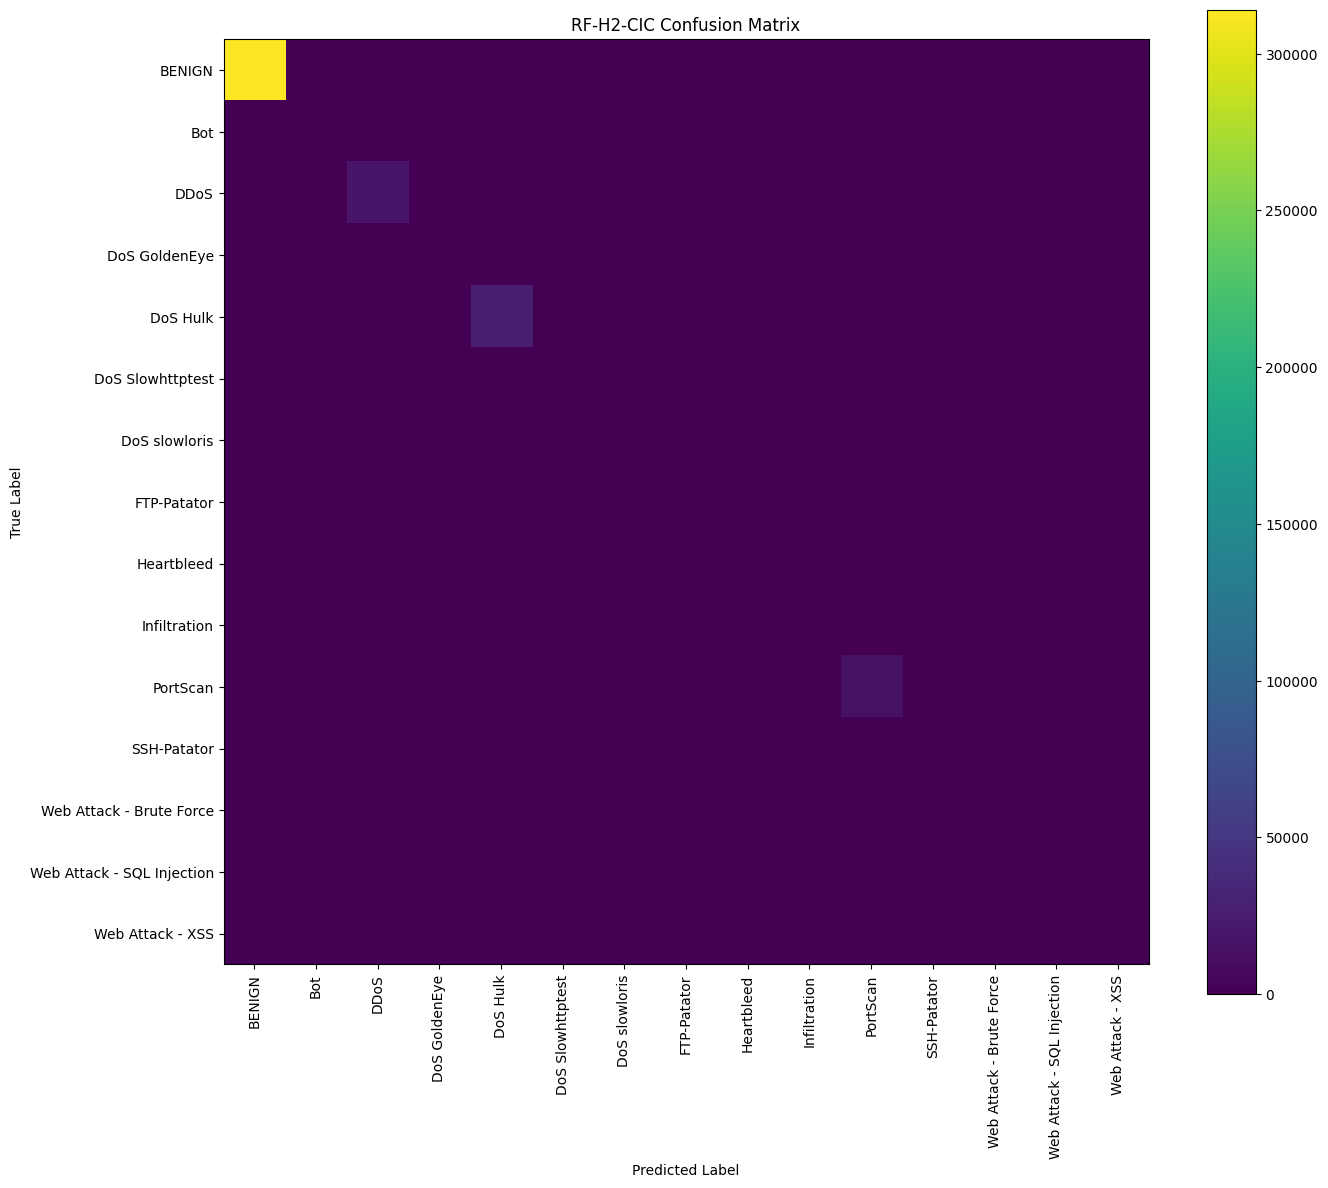

RF-H2-CIC confusion matrix saved to:
/content/drive/MyDrive/MSc_Project/results/RF_H2_CIC/RF_H2_CIC_confusion_matrix.png

File exists: True


In [ ]:
# Cell 36 — RF-H2-CIC final confusion matrix

from sklearn.metrics import confusion_matrix

cm_h2 = confusion_matrix(
    y_true_h2,
    y_pred_h2,
    labels=class_names
)

plt.figure(
    figsize=(14, 12)
)

plt.imshow(
    cm_h2,
    interpolation="nearest"
)

plt.title(
    "RF-H2-CIC Confusion Matrix"
)

plt.colorbar()

tick_marks = np.arange(
    len(class_names)
)

plt.xticks(
    tick_marks,
    class_names,
    rotation=90
)

plt.yticks(
    tick_marks,
    class_names
)

plt.xlabel(
    "Predicted Label"
)

plt.ylabel(
    "True Label"
)

plt.tight_layout()

H2_CM_PATH = os.path.join(
    RESULTS_DIR,
    "RF_H2_CIC_confusion_matrix.png"
)

plt.savefig(
    H2_CM_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    "RF-H2-CIC confusion matrix saved to:"
)

print(
    H2_CM_PATH
)

print(
    "\nFile exists:",
    os.path.exists(
        H2_CM_PATH
    )
)

In [ ]:
# Cell 37 — Save final RF-H2-CIC metrics
# and compare RF-B-CIC vs RF-H1-CIC vs RF-H2-CIC

# --------------------------------------------------
# 1. Save final RF-H2-CIC test metrics
# --------------------------------------------------

H2_METRICS_PATH = os.path.join(
    RESULTS_DIR,
    "RF_H2_CIC_metrics.csv"
)

h2_final_metrics_df = pd.DataFrame([
    {
        "Model": "RF-H2-CIC",
        "Trees": FINAL_H2_TREES,
        "Accuracy": results_h2_test["Accuracy"],
        "Macro Precision": results_h2_test["Macro Precision"],
        "Macro Recall": results_h2_test["Macro Recall"],
        "Macro F1": results_h2_test["Macro F1"],
        "Weighted F1": results_h2_test["Weighted F1"],
        "Balanced Accuracy": results_h2_test["Balanced Accuracy"],
        "MCC": results_h2_test["MCC"],
        "Training Time Seconds": FINAL_H2_TRAINING_TIME
    }
])

h2_final_metrics_df.to_csv(
    H2_METRICS_PATH,
    index=False
)

print(
    "RF-H2-CIC final metrics saved to:"
)

print(
    H2_METRICS_PATH
)

# --------------------------------------------------
# 2. Load frozen RF-B-CIC and RF-H1-CIC metrics
# --------------------------------------------------

RF_B_METRICS_PATH = os.path.join(
    PROJECT_DIR,
    "results",
    "RF_B_CIC",
    "RF_B_CIC_metrics.csv"
)

RF_H1_METRICS_PATH = os.path.join(
    PROJECT_DIR,
    "results",
    "RF_H1_CIC",
    "RF_H1_CIC_metrics.csv"
)

rf_b_metrics_df = pd.read_csv(
    RF_B_METRICS_PATH
)

rf_h1_metrics_df = pd.read_csv(
    RF_H1_METRICS_PATH
)

# --------------------------------------------------
# 3. Add frozen configuration information
# --------------------------------------------------

# RF-B-CIC frozen configuration
rf_b_metrics_df["Model"] = "RF-B-CIC"
rf_b_metrics_df["Trees"] = 100

# RF-H1-CIC frozen winning configuration
rf_h1_metrics_df["Model"] = "RF-H1-CIC"
rf_h1_metrics_df["Trees"] = 300

# --------------------------------------------------
# 4. Check required metric columns
# --------------------------------------------------

required_metric_columns = [
    "Accuracy",
    "Macro Precision",
    "Macro Recall",
    "Macro F1",
    "Weighted F1",
    "Balanced Accuracy",
    "MCC",
    "Training Time Seconds"
]

for model_name, df in [
    ("RF-B-CIC", rf_b_metrics_df),
    ("RF-H1-CIC", rf_h1_metrics_df),
    ("RF-H2-CIC", h2_final_metrics_df)
]:
    missing_columns = [
        col
        for col in required_metric_columns
        if col not in df.columns
    ]

    if missing_columns:
        raise KeyError(
            f"{model_name} is missing columns: "
            f"{missing_columns}"
        )

print(
    "\nAll required metric columns verified."
)

# --------------------------------------------------
# 5. Build final comparison
# --------------------------------------------------

comparison_columns = [
    "Model",
    "Trees",
    "Accuracy",
    "Macro Precision",
    "Macro Recall",
    "Macro F1",
    "Weighted F1",
    "Balanced Accuracy",
    "MCC",
    "Training Time Seconds"
]

rf_b_compare = rf_b_metrics_df[
    comparison_columns
].copy()

rf_h1_compare = rf_h1_metrics_df[
    comparison_columns
].copy()

rf_h2_compare = h2_final_metrics_df[
    comparison_columns
].copy()

final_comparison_df = pd.concat(
    [
        rf_b_compare,
        rf_h1_compare,
        rf_h2_compare
    ],
    ignore_index=True
)

# --------------------------------------------------
# 6. Save final comparison
# --------------------------------------------------

FINAL_COMPARISON_PATH = os.path.join(
    RESULTS_DIR,
    "RF_B_vs_RF_H1_vs_RF_H2_test_comparison.csv"
)

final_comparison_df.to_csv(
    FINAL_COMPARISON_PATH,
    index=False
)

print(
    "\nRF-B-CIC vs RF-H1-CIC vs RF-H2-CIC "
    "Final Test Comparison"
)

display(
    final_comparison_df
)

print(
    "\nComparison saved to:"
)

print(
    FINAL_COMPARISON_PATH
)

# --------------------------------------------------
# 7. Final artefact checks
# --------------------------------------------------

print(
    "\nFinal checks:"
)

print(
    "H2 metrics file exists:",
    os.path.exists(
        H2_METRICS_PATH
    )
)

print(
    "Classification report exists:",
    os.path.exists(
        H2_REPORT_PATH
    )
)

print(
    "Confusion matrix exists:",
    os.path.exists(
        H2_CM_PATH
    )
)

print(
    "Final model exists:",
    os.path.exists(
        FINAL_H2_MODEL_PATH
    )
)

print(
    "Comparison file exists:",
    os.path.exists(
        FINAL_COMPARISON_PATH
    )
)

RF-H2-CIC final metrics saved to:
/content/drive/MyDrive/MSc_Project/results/RF_H2_CIC/RF_H2_CIC_metrics.csv

All required metric columns verified.

RF-B-CIC vs RF-H1-CIC vs RF-H2-CIC Final Test Comparison


,Model,Trees,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1,Balanced Accuracy,MCC,Training Time Seconds
0,RF-B-CIC,100,0.998606,0.935485,0.879297,0.893851,0.998570,0.879297,0.995364,302.872033
1,RF-H1-CIC,300,0.998622,0.933633,0.879613,0.893381,0.998588,0.879613,0.995417,748.276625
2,RF-H2-CIC,100,0.998707,0.932351,0.874790,0.888474,0.998655,0.874790,0.995699,315.334803



Comparison saved to:
/content/drive/MyDrive/MSc_Project/results/RF_H2_CIC/RF_B_vs_RF_H1_vs_RF_H2_test_comparison.csv

Final checks:
H2 metrics file exists: True
Classification report exists: True
Confusion matrix exists: True
Final model exists: True
Comparison file exists: True
